In [2]:
import pandas as pd, numpy as np
df = pd.read_csv("/content/sales_working.csv")
print(df.shape)
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
df.head()

(9800, 18)
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64
Duplicates: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12-06-2017,16-06-2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
np.random.seed(42)
messy = df.copy()
# missing values
messy.loc[messy.sample(frac=0.03).index, "Sales"] = np.nan
messy.loc[messy.sample(frac=0.02).index, "Region"] = np.nan
# inconsistent text
idx = messy.sample(frac=0.05).index
messy.loc[idx, "Region"] = messy.loc[idx, "Region"].str.upper()
idx = messy.sample(frac=0.05).index
messy.loc[idx, "Category"] = " " + messy.loc[idx, "Category"].astype(str) + " "
# duplicates
messy = pd.concat([messy, messy.sample(100)], ignore_index=True)
messy.to_csv("messy_sales.csv", index=False)
print(messy.shape)

(9900, 18)


In [4]:
def clean_data(path):
    d = pd.read_csv(path)
    log = {"rows_start": len(d)}
    d = d.drop_duplicates()
    log["duplicates_removed"] = log["rows_start"] - len(d)
    # standardize text
    for c in ["Region", "Category", "Sub-Category", "Segment", "Ship Mode"]:
        d[c] = d[c].astype("string").str.strip().str.title()
    # dates
    d["Order Date"] = pd.to_datetime(d["Order Date"], dayfirst=True, errors="coerce")
    d["Ship Date"] = pd.to_datetime(d["Ship Date"], dayfirst=True, errors="coerce")
    # missing values
    log["missing_before"] = int(d.isna().sum().sum())
    d["Sales"] = d["Sales"].fillna(d.groupby("Sub-Category")["Sales"].transform("median"))
    d["Region"] = d["Region"].fillna("Unknown")
    d["Postal Code"] = d["Postal Code"].fillna(0).astype(int)
    log["missing_after"] = int(d.isna().sum().sum())
    log["rows_end"] = len(d)
    return d, log

clean, log = clean_data("messy_sales.csv")
log

{'rows_start': 9900,
 'duplicates_removed': 100,
 'missing_before': 501,
 'missing_after': 0,
 'rows_end': 9800}

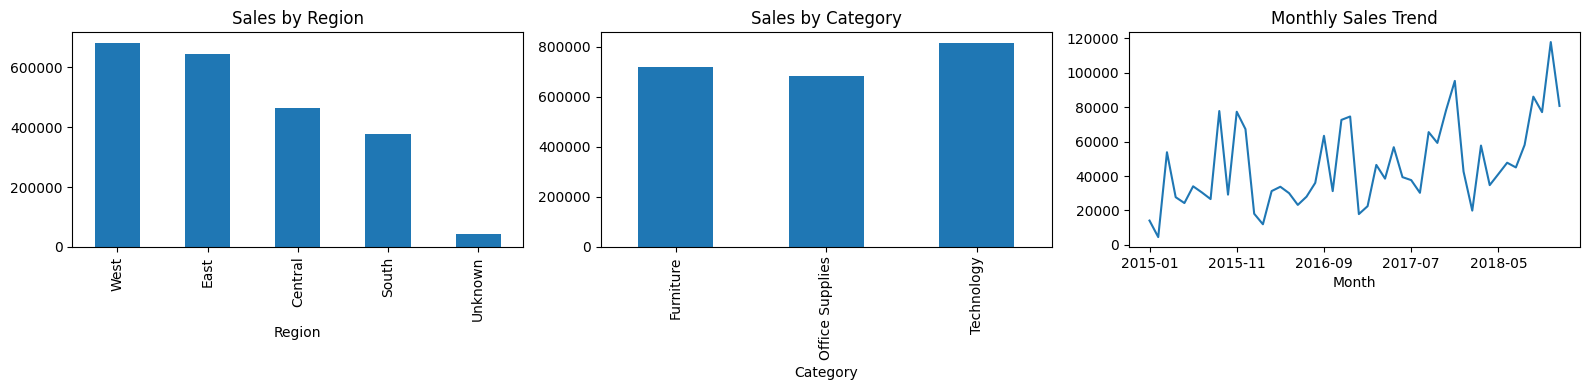

In [5]:
import matplotlib.pyplot as plt

def make_report(d, log, out="Sales_Report.xlsx"):
    by_region = d.groupby("Region")["Sales"].sum().sort_values(ascending=False)
    by_cat = d.groupby("Category")["Sales"].sum()
    d["Month"] = d["Order Date"].dt.to_period("M").astype(str)
    trend = d.groupby("Month")["Sales"].sum()

    with pd.ExcelWriter(out) as w:
        pd.DataFrame([log]).T.rename(columns={0: "Value"}).to_excel(w, sheet_name="Cleaning Log")
        by_region.to_excel(w, sheet_name="By Region")
        by_cat.to_excel(w, sheet_name="By Category")
        trend.to_excel(w, sheet_name="Monthly Trend")
        d.to_excel(w, sheet_name="Clean Data", index=False)

    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    by_region.plot(kind="bar", ax=ax[0], title="Sales by Region")
    by_cat.plot(kind="bar", ax=ax[1], title="Sales by Category")
    trend.plot(ax=ax[2], title="Monthly Sales Trend")
    plt.tight_layout()
    plt.savefig("report_charts.png")
    plt.show()

make_report(clean, log)

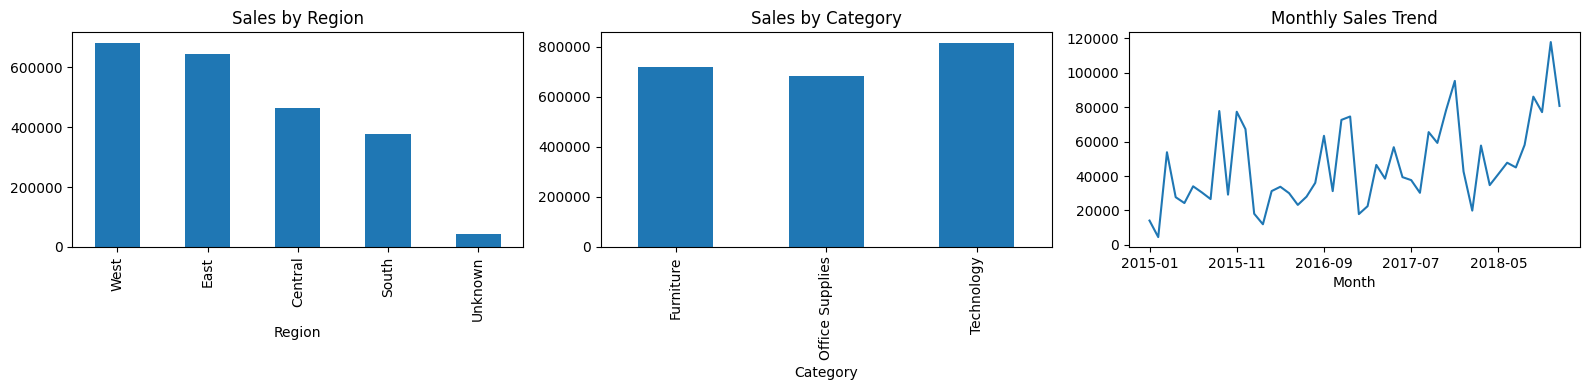

Pipeline finished: {'rows_start': 9900, 'duplicates_removed': 100, 'missing_before': 501, 'missing_after': 0, 'rows_end': 9800}


In [6]:
d, log = clean_data("messy_sales.csv")
make_report(d, log)
print("Pipeline finished:", log)

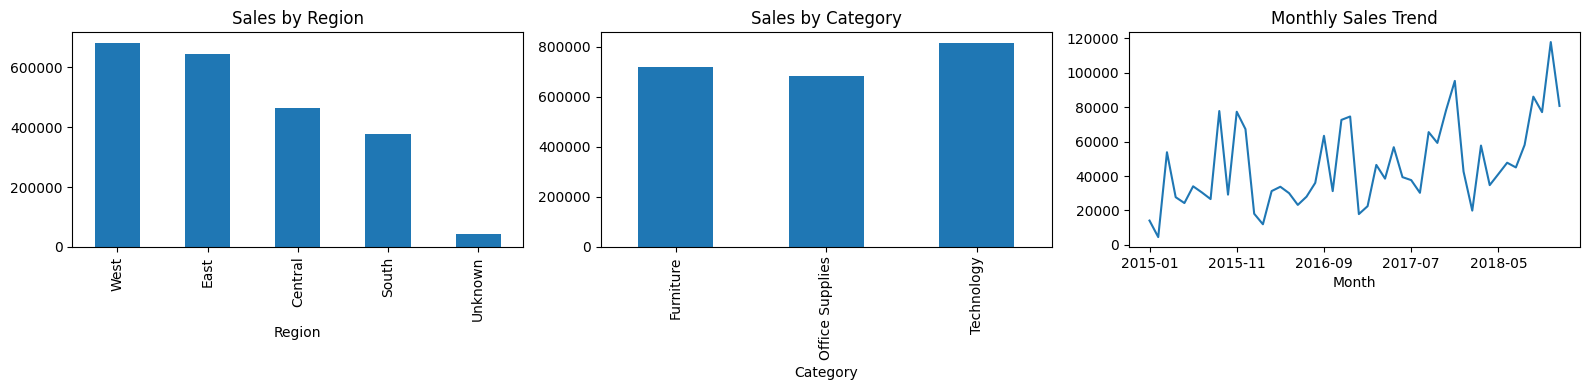

In [7]:
d, log = clean_data("messy_sales.csv")
make_report(d, log)